# Portfolio Allocation Project — Part 1: Data Pipeline

**Goal of this notebook:** download ~10 years of daily prices for 10 ETFs covering different asset classes, convert them to daily log returns, and explore their statistical properties (fat tails, skewness, and how correlations change in crises and across market regimes) before any optimization.

**Output:** `prices.csv` (adjusted prices) and `returns.csv` (daily log returns), which the next notebooks will use.

If `yfinance` or `plotly` aren't installed yet, run this once in a terminal:
```
pip install yfinance plotly nbformat
```

In [16]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import plotly.graph_objects as go

## 1. Choose the assets

One ETF per asset class. The order of this list defines the position of each asset in every vector and matrix later on ($\mathbf a$, $\mathbf Y$, $\boldsymbol\mu$, $\Sigma$), so we keep it fixed.

In [9]:
assets = {
    "SPY":  "U.S. large stocks (S&P 500)",
    "IWM":  "U.S. small stocks (Russell 2000)",
    "EFA":  "Developed international stocks",
    "EEM":  "Emerging-market stocks",
    "TLT":  "Long U.S. Treasuries (20+ yr)",
    "IEF":  "Intermediate U.S. Treasuries (7-10 yr)",
    "LQD":  "Investment-grade corporate bonds",
    "EMLC": "Emerging-market local-currency bonds",
    "GLD":  "Gold",
    "VNQ":  "U.S. real estate (REITs)",
}
tickers = list(assets.keys())
K = len(tickers)

START = "2016-01-01"
END = "2026-10-30"   # yfinance excludes the end date
print(f"K = {K} assets")

K = 10 assets


## 2. Download adjusted prices (or load them if already saved)

`auto_adjust=True` adjusts prices for dividends and splits. This matters a lot for bond ETFs, whose return is mostly dividends.

The download only happens the first time; after that the notebook reads `prices.csv`, so results don't change every time you rerun it.

In [3]:
PRICES_FILE = "prices.csv"

if os.path.exists(PRICES_FILE):
    prices = pd.read_csv(PRICES_FILE, index_col=0, parse_dates=True)
    print("Loaded prices from file.")
else:
    raw = yf.download(tickers, start=START, end=END, auto_adjust=True, progress=False)
    prices = raw["Close"]
    prices.to_csv(PRICES_FILE)
    print("Downloaded and saved prices.")

# yfinance sorts columns alphabetically: put them back in our fixed order
prices = prices[tickers]
prices.tail()

Downloaded and saved prices.


Ticker,SPY,IWM,EFA,EEM,TLT,IEF,LQD,EMLC,GLD,VNQ
Date,,,,,,,,,,
2026-10-23,759.969971,275.750000,102.629997,62.009998,81.339996,91.050003,103.849998,24.799999,366.609985,92.690002
2026-10-26,765.369995,276.989990,102.910004,61.820000,81.680000,91.120003,104.019997,24.580000,367.820007,93.169998
2026-10-27,769.659973,280.179993,103.589996,62.520000,81.629997,91.099998,104.300003,24.629999,372.279999,92.389999
2026-10-28,772.309998,281.290009,103.680000,63.520000,80.989998,90.849998,104.070000,24.620001,373.510010,91.790001
2026-10-29,769.359985,284.010010,104.349998,62.720001,81.489998,91.250000,104.220001,24.639999,368.570007,93.870003


## 3. Sanity checks on prices

- Does every ETF start at the beginning of the sample?
- Are there missing values?

In [4]:
checks = pd.DataFrame({
    "first_date": prices.apply(lambda s: s.first_valid_index().date()),
    "last_date": prices.apply(lambda s: s.last_valid_index().date()),
    "missing_values": prices.isna().sum(),
})
print(f"Trading days: {len(prices)}")
checks

Trading days: 2722


,first_date,last_date,missing_values
Ticker,,,
SPY,2016-01-04,2026-10-29,0
IWM,2016-01-04,2026-10-29,0
EFA,2016-01-04,2026-10-29,0
EEM,2016-01-04,2026-10-29,0
TLT,2016-01-04,2026-10-29,0
IEF,2016-01-04,2026-10-29,0
LQD,2016-01-04,2026-10-29,0
EMLC,2016-01-04,2026-10-29,0
GLD,2016-01-04,2026-10-29,0


## 4. Prices → daily log returns

$r_t = \ln(P_t) - \ln(P_{t-1})$. Each row of `returns` is one realization of the random vector $\mathbf Y$; each column is one asset's history. This is the data matrix $R$ ($T \times K$).

In [5]:
returns = np.log(prices).diff().dropna()
returns.to_csv("returns.csv")
print(f"R has shape {returns.shape}  (T days x K assets)")
returns.head()

R has shape (2721, 10)  (T days x K assets)


Ticker,SPY,IWM,EFA,EEM,TLT,IEF,LQD,EMLC,GLD,VNQ
Date,,,,,,,,,,
2016-01-05,0.001690,0.002179,-0.001558,0.002234,-0.004043,-0.000284,0.000527,0.000593,0.002815,0.019113
2016-01-06,-0.012694,-0.015355,-0.016593,-0.019306,0.013385,0.006020,0.003938,-0.011933,0.014337,-0.002744
2016-01-07,-0.024284,-0.027074,-0.021001,-0.031351,0.001793,0.002154,0.000786,-0.001202,0.014041,-0.019675
2016-01-08,-0.011037,-0.017373,-0.012123,-0.010785,0.004468,0.002523,0.000785,-0.000600,-0.004438,-0.013465
2016-01-11,0.000990,-0.004343,0.004178,-0.000339,-0.011003,-0.003178,-0.003232,-0.001806,-0.008935,0.005664


## 5. Summary statistics (annualized)

Daily numbers are tiny and hard to read, so we annualize: mean × 252 and standard deviation × $\sqrt{252}$ (about 252 trading days per year).

We also look at two shape statistics that a normal distribution cannot capture:

- **Skewness**: 0 for a symmetric distribution. Negative values mean the left tail is longer: large losses are more likely than equally large gains.
- **Excess kurtosis**: 0 for a normal distribution. Large positive values mean fat tails, i.e. extreme days happen more often than the Gaussian model assumes.

In [6]:
summary = pd.DataFrame({
    "description": pd.Series(assets),
    "ann_mean_return": returns.mean() * 252,
    "ann_volatility": returns.std() * np.sqrt(252),
    "skewness": returns.skew(),
    "excess_kurtosis": returns.kurt(),
})
summary.round(3)

,description,ann_mean_return,ann_volatility,skewness,excess_kurtosis
SPY,U.S. large stocks (S&P 500),0.140,0.177,-0.593,15.194
IWM,U.S. small stocks (Russell 2000),0.100,0.228,-0.698,8.833
EFA,Developed international stocks,0.084,0.173,-1.061,15.424
EEM,Emerging-market stocks,0.085,0.210,-0.714,8.680
TLT,Long U.S. Treasuries (20+ yr),-0.009,0.147,0.023,5.077
IEF,Intermediate U.S. Treasuries (7-10 yr),0.009,0.065,0.149,3.261
LQD,Investment-grade corporate bonds,0.027,0.085,0.279,28.502
EMLC,Emerging-market local-currency bonds,0.028,0.101,-1.274,11.438
GLD,Gold,0.118,0.165,-0.640,7.522
VNQ,U.S. real estate (REITs),0.056,0.206,-1.526,26.120


### Robustness check: excluding the COVID crash

Sample skewness and kurtosis are driven by a handful of extreme days. To see how much a single event matters, we recompute the summary excluding **20 Feb – 30 Apr 2020**, the COVID crash and the Fed's rescue response.


In [11]:
covid = (returns.index >= "2020-02-20") & (returns.index <= "2020-04-30")
returns_ex = returns[~covid]

summary_ex = pd.DataFrame({
    "description": pd.Series(assets),
    "ann_mean_return": returns_ex.mean() * 252,
    "ann_volatility": returns_ex.std() * np.sqrt(252),
    "skewness": returns_ex.skew(),
    "excess_kurtosis": returns_ex.kurt(),
})
summary_ex.round(3)


,description,ann_mean_return,ann_volatility,skewness,excess_kurtosis
SPY,U.S. large stocks (S&P 500),0.157,0.154,-0.203,7.397
IWM,U.S. small stocks (Russell 2000),0.126,0.205,-0.123,2.309
EFA,Developed international stocks,0.104,0.154,-0.377,6.634
EEM,Emerging-market stocks,0.105,0.193,-0.176,2.606
TLT,Long U.S. Treasuries (20+ yr),-0.022,0.137,-0.063,1.057
IEF,Intermediate U.S. Treasuries (7-10 yr),0.003,0.063,0.100,1.995
LQD,Investment-grade corporate bonds,0.028,0.070,-0.085,2.955
EMLC,Emerging-market local-currency bonds,0.042,0.093,-0.643,5.712
GLD,Gold,0.116,0.162,-0.705,7.992
VNQ,U.S. real estate (REITs),0.080,0.174,-0.176,2.971


**Takeaways**

- **Kurtosis collapses once the COVID window is removed.** LQD falls from 28.5 to 3.0 and VNQ from 26.1 to 3.0; IWM, EEM and TLT also drop to between 1 and 3. A few weeks in early 2020 explain most of the fat tails in the full sample. Gold is the exception: its kurtosis is unchanged (7.5 → 8.0), so its extreme days are spread across the sample rather than concentrated in the crash.
- **The negative skew of risk assets mostly disappears.** VNQ goes from −1.53 to −0.18, EFA from −1.06 to −0.38 and IWM from −0.70 to −0.12. The strong left tail of these assets comes largely from the March 2020 crash. For the bonds, TLT and LQD flip from slightly positive to slightly negative skew, since their best days were the flight-to-safety and Fed-rescue rallies; IEF stays mildly positive.
- **Without the crash, equities look better and less risky** (SPY: mean 14.0% → 15.7%, volatility 17.7% → 15.4%), which shows how much a single event shapes the historical inputs.
- **TLT's annualized mean return falls from −0.9% to −2.2%.** TLT's best days happened exactly when equities were crashing. Its value as a crisis hedge shows up in its co-movement with stocks during stress, not in its average return.


**Implications for the portfolio model**

1. Sample skewness and kurtosis are unstable, since their sign and size depend on a few days. We use them as **diagnostics**, not as criteria to include or exclude assets.
2. Normality is clearly violated, so mean-variance results should be complemented with tail-risk measures (e.g. CVaR, maximum drawdown) on the final portfolios.
3. Historical mean returns are period-dependent (see TLT). Expected-return inputs to the optimizer should be treated with caution.
4. We do **not** drop the COVID period when estimating the model: the crash is exactly the kind of event a robust portfolio must withstand. How much history to use is a separate question, addressed later with rolling and EWMA estimates.

## 6. Growth of $1 invested in each asset

Since log returns add up over time, $\exp(\text{cumulative sum})$ gives the value of \$1 invested at the start.

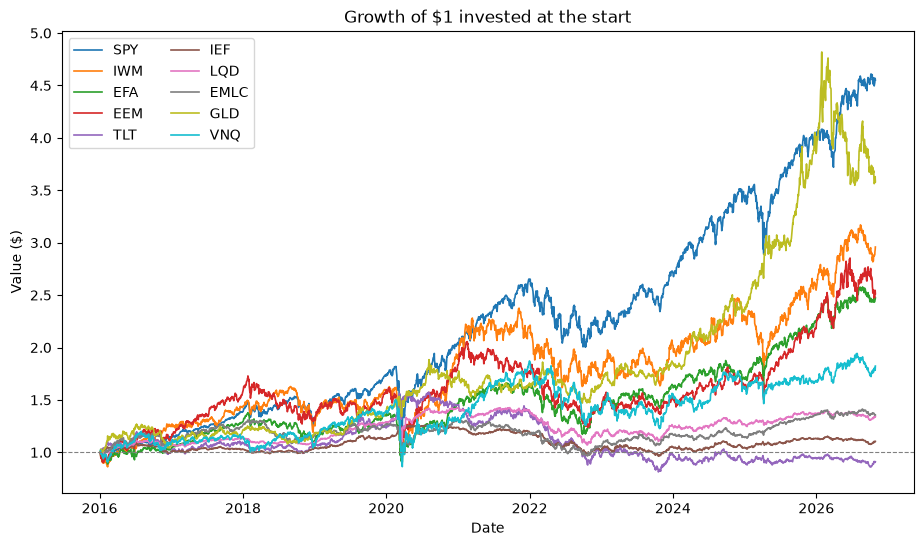

In [7]:
growth = np.exp(returns.cumsum())

fig, ax = plt.subplots(figsize=(11, 6))
for t in tickers:
    ax.plot(growth.index, growth[t], label=t, linewidth=1.2)
ax.axhline(1, color="gray", linewidth=0.8, linestyle="--")
ax.set_title("Growth of $1 invested at the start")
ax.set_xlabel("Date")
ax.set_ylabel("Value ($)")
ax.legend(ncol=2)
plt.show()

## 7. Correlation matrix

The off-diagonal structure of $\Sigma$ is where diversification and hedging come from. Correlations are easier to read than covariances because they are all on the same −1 to 1 scale.

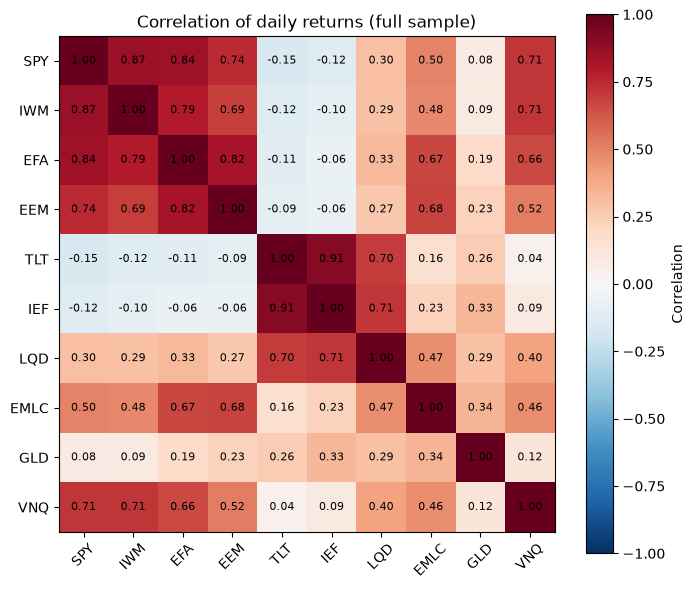

In [8]:
corr = returns.corr()

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(K))
ax.set_yticks(range(K))
ax.set_xticklabels(tickers, rotation=45)
ax.set_yticklabels(tickers)
for i in range(K):
    for j in range(K):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="Correlation")
ax.set_title("Correlation of daily returns (full sample)")
plt.show()

## 8. Correlations under stress: does diversification hold in a crisis?

The full-sample correlation matrix above summarizes ten years of data in a single number per pair. For portfolio construction, however, what matters most is how assets co-move **when markets are under stress**, because that is when diversification is needed. A portfolio built on calm-period correlations may be far riskier in a crash than the model suggests.

We use the COVID crash (**20 Feb – 30 Apr 2020**) as a stress episode and compare it with the rest of the sample. We look at **correlations rather than covariances**: in a crisis the volatility of almost every asset spikes, so covariances rise even if the assets do not move more closely together. Correlations remove this scale effect and isolate the change in co-movement.

The analysis has three parts:

1. **Ex-COVID vs COVID-only correlation matrices**, side by side, to compare normal times with the crisis.
2. **Difference matrix (COVID − ex-COVID).** Red cells are pairs that moved more closely together during the crash (diversification weakened). Blue cells are pairs that diverged (hedging improved).
3. **Rolling 6-month correlation between SPY and TLT**, to check whether the stock–bond relationship is stable over time or changes across market regimes.


COVID window: 50 trading days


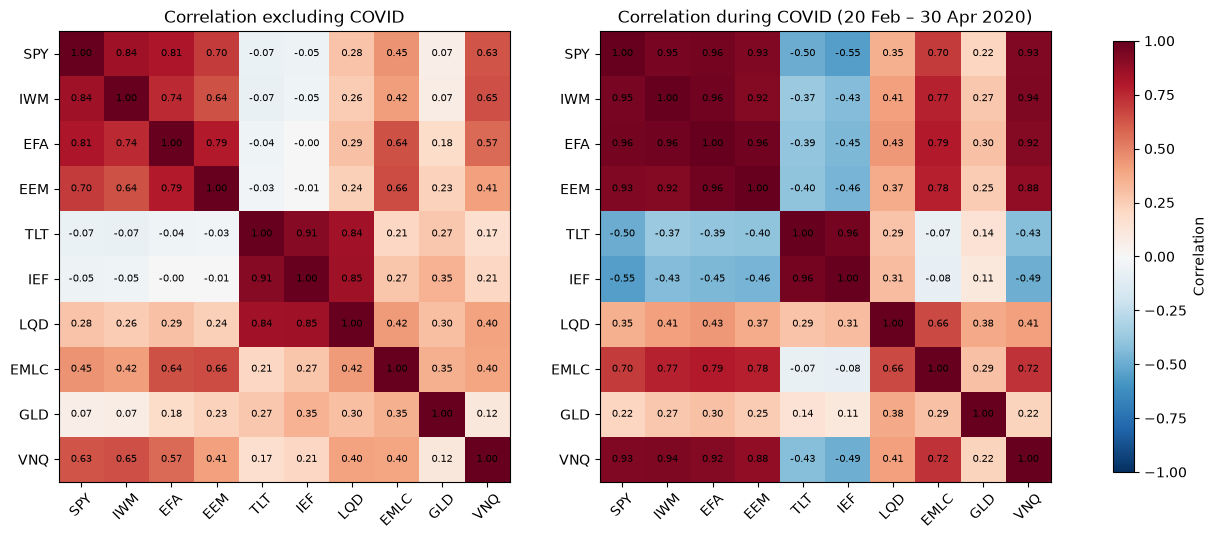

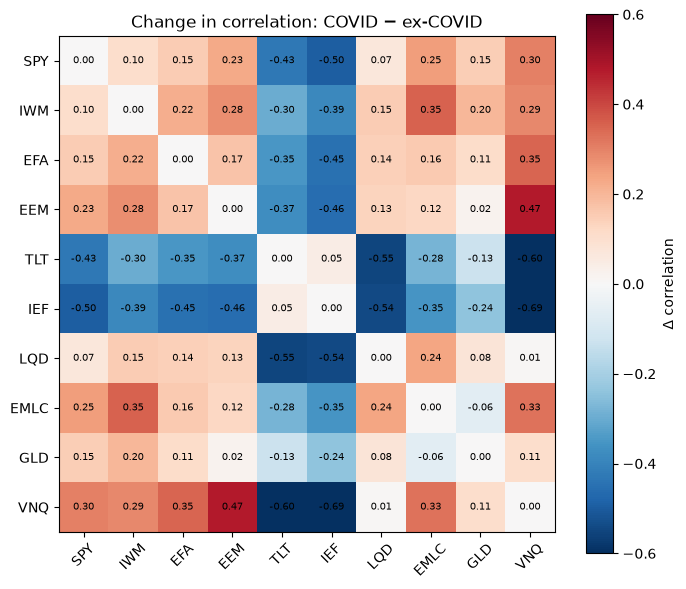

In [12]:
covid = (returns.index >= "2020-02-20") & (returns.index <= "2020-04-30")
corr_covid = returns[covid].corr()
corr_ex = returns[~covid].corr()
corr_diff = corr_covid - corr_ex

print(f"COVID window: {covid.sum()} trading days")

def plot_corr(ax, m, title, vmin=-1, vmax=1):
    im = ax.imshow(m, cmap="RdBu_r", vmin=vmin, vmax=vmax)
    ax.set_xticks(range(K))
    ax.set_yticks(range(K))
    ax.set_xticklabels(tickers, rotation=45)
    ax.set_yticklabels(tickers)
    for i in range(K):
        for j in range(K):
            ax.text(j, i, f"{m.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
    ax.set_title(title)
    return im

# 1) Ex-COVID vs COVID only
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
plot_corr(axes[0], corr_ex, "Correlation excluding COVID")
im = plot_corr(axes[1], corr_covid, "Correlation during COVID (20 Feb – 30 Apr 2020)")
fig.colorbar(im, ax=axes, label="Correlation", shrink=0.8)
plt.show()

# 2) Difference: what changed during the crisis
fig, ax = plt.subplots(figsize=(8, 7))
im = plot_corr(ax, corr_diff, "Change in correlation: COVID − ex-COVID", vmin=-0.6, vmax=0.6)
fig.colorbar(im, ax=ax, label="Δ correlation")
plt.show()


**Takeaways: correlations during the COVID crash**

- **Treasuries worked as a hedge.** During the crash, the correlation of TLT and IEF with equities became more negative: investors fled to safety and the Fed cut rates to zero, so long bonds rallied while stocks fell.
- **Diversification among risk assets weakened.** Equities, REITs, EM bonds and corporate bonds moved more closely together during the sell-off. Assets that look like diversifiers in normal times can fail precisely when protection is needed.
- **Gold did not hedge during the crash:** its correlation with SPY rose from 0.07 to 0.22, consistent with the "sell everything for cash" phase of March 2020.
- **Corporate bonds decoupled from Treasuries:** LQD's correlation with TLT and IEF fell by about 0.55. Credit risk dominated, so LQD behaved more like a risk asset than a safe haven.
- **Caveat:** the COVID window has only 50 trading days, so these correlations are noisy. They illustrate a pattern rather than give precise estimates.


The matrices above compare two fixed periods. To see how the stock–bond relationship evolves continuously, we compute the correlation between SPY and TLT over a rolling window of 126 trading days (about six months).


In [18]:
# 3) Rolling 6-month correlation between stocks and long bonds
roll = returns["SPY"].rolling(126).corr(returns["TLT"])

fig = go.Figure()
fig.add_trace(go.Scatter(x=roll.index, y=roll, mode="lines", name="SPY–TLT"))

fig.add_hline(y=0, line_dash="dash", line_color="gray")

# COVID crash
fig.add_vrect(x0="2020-02-20", x1="2020-04-30", fillcolor="red", opacity=0.15,
              line_width=0, annotation_text="COVID crash", annotation_position="top left")

# Fed hiking cycle (inflation shock)
fig.add_vrect(x0="2022-03-16", x1="2023-07-26", fillcolor="orange", opacity=0.15,
              line_width=0, annotation_text="Fed hiking cycle", annotation_position="top left")

fig.update_layout(
    title="SPY–TLT correlation over time (rolling 126-day window)",
    yaxis_title="Correlation (past 126 trading days)",
    height=500,
    xaxis=dict(
        rangeslider=dict(visible=True),
        rangeselector=dict(buttons=[
            dict(count=6, label="6M", step="month", stepmode="backward"),
            dict(count=1, label="1Y", step="year", stepmode="backward"),
            dict(count=3, label="3Y", step="year", stepmode="backward"),
            dict(step="all", label="All"),
        ]),
    ),
)
fig.show()


**Takeaways: the stock–bond correlation is regime-dependent**

The rolling correlation between SPY and TLT was negative for most of 2016–2021, around −0.5 in 2019–2020, including the COVID crash. It turns positive in the second half of 2022 and has been mostly positive since, though not monotonically: it drops back toward zero in late 2024–2025 and reaches its highest level of the sample (about +0.45) in 2026. (The dip in late 2021 should not be over-interpreted: a 6-month rolling window is noisy and lags events by up to six months.)

The sign of the correlation depends on which macro risk dominates:

| Regime | Dominant risk | Bad news leads to… | Stock–bond correlation |
|---|---|---|---|
| ~2000–2021 | Growth (recessions, panics) | Stocks fall, Fed cuts rates, bonds rally | Negative |
| 2022 onward | Inflation and interest rates | High inflation → Fed hikes or holds rates → stocks and bonds fall together | Positive |

In 2022, the Fed's aggressive hikes to fight inflation hit both asset classes at once, and TLT lost roughly 30%. Since then, markets have remained focused on the path of policy rates, and strong economic data can be "bad news" for both stocks and bonds because it implies higher rates for longer. The negative correlation of 2000–2021 is in fact the historical exception: during the inflation-driven 1970s–1990s, the stock–bond correlation was also positive.

Note that the correlation remains mostly positive after the hiking cycle ends in July 2023 (with a temporary return toward zero in late 2024–2025). The driver is not the hikes themselves but the fact that inflation and the path of interest rates remained the dominant source of market risk: every inflation or labor-market release shifted rate expectations and moved stocks and bonds in the same direction, both down (higher for longer) and up (e.g. the joint rally of late 2023 when markets anticipated cuts). Long-term yields are also driven by fiscal deficits and Treasury supply, not only by the policy rate. Stock–bond correlation regimes tend to be persistent, which is why we treat 2022 as a regime change rather than a one-off event.

**Implications for the model**

1. A single full-sample covariance matrix averages two very different regimes. Time-varying estimates (rolling window or EWMA) are more appropriate in the backtest.
2. Optimal weights depend on the estimation window. With recent data, TLT looks like a volatile asset that no longer diversifies, while IEF may keep a large weight because of its low volatility.
3. Long-duration Treasuries protect against **growth shocks**, not **inflation shocks**. An effective hedge needs exposures that also work when rates rise.

**Hedging alternatives for an inflation regime**

| Hedge | Example ETFs | Why it can help | Limitation |
|---|---|---|---|
| Gold (already in our universe) | GLD | Historically a store of value during inflation and monetary stress | Can fall in liquidity crunches (e.g. March 2020) and has no cash flows |
| Short-duration Treasuries / T-bills | SGOV, BIL, SHY | Little sensitivity to rate hikes; they benefit from higher yields | Little upside in a crash; mainly reduce risk rather than hedge |
| Inflation-protected bonds (TIPS) | TIP, SCHP; short-duration VTIP | Principal is indexed to inflation | Long TIPS still fell in 2022 as real rates rose; short duration works better |
| Broad commodities | DBC, PDBC | Directly linked to inflation drivers (energy, metals, agriculture); rose strongly in 2022 | Very volatile, long flat periods, roll costs |
| Trend-following / managed futures | DBMF, KMLM | Can go long or short across assets; delivered strong positive returns in 2022 when stocks and bonds fell together | Strategy risk, higher fees, can underperform for years |
| Explicit tail protection | Put options, long-volatility strategies | Pay off directly in crashes | Costly to hold over time (negative carry) |

**Possible extensions:** (i) add one or two of these assets (e.g. SGOV, TIP or DBC) to the universe and check how the efficient portfolios change; (ii) estimate the minimum-variance portfolio on 2016–2021 data and evaluate it out of sample on 2022–2026 to measure the cost of assuming a stable covariance matrix.

## 9. Summary of findings and next steps

**What we learned from the data**

1. **Clean data:** 10 ETFs with complete daily prices from January 2016 to October 2026 (2,721 daily log returns, no missing values).
2. **Returns are not normal.** All assets show fat tails, and most risky assets show negative skew. A large share of this comes from a single event, the COVID crash, so sample skewness and kurtosis are unstable and are used as diagnostics only.
3. **Historical means are period-dependent.** TLT has a negative average return in this sample, driven by the 2022 rate shock. Historical means are a weak guide to expected returns.
4. **Diversification weakens in a crisis.** During the COVID crash, equities, REITs and EM bonds became much more correlated with each other. Treasuries (TLT, IEF) hedged; gold and corporate bonds did not.
5. **The stock–bond correlation depends on the regime.** It was negative until 2021 (growth-driven market) and has been mostly positive since 2022 (inflation- and rate-driven market). A single full-sample covariance matrix mixes both regimes.

**Next steps for the optimization notebook**

- Start with the **minimum-variance portfolio**, which only needs $\Sigma$, then add **mean-variance with constraints** (e.g. no short sales, maximum weights).
- Estimate $\Sigma$ with a **rolling 2–3 year window** (504–756 trading days) or **EWMA with a 6–12 month half-life**, and compare it with the full-sample and Ledoit-Wolf shrinkage estimates.
- Run an **out-of-sample backtest with monthly rebalancing**. With a 3-year estimation window, the test period starts in 2019 and includes both the COVID crash and the 2022 regime change.
- Evaluate portfolios with **volatility, Sharpe ratio, historical CVaR, maximum drawdown and turnover**, since the normal distribution understates tail risk.

**Questions to keep in mind**

1. Which asset had the **lowest** annualized volatility? Do you expect it to get a large weight in the minimum-variance portfolio? Why might the correlations change that answer?
2. Which pairs have the **highest** correlations (above ~0.8)? Remember the hedge example: high correlation + different volatilities is where the formula wants to short.
3. Which pairs have **negative or near-zero** correlations? Those are the diversifiers, and how stable are they across regimes?